# Lab B - Activation functions
An activation adds non-linearity so stacked layers can learn more than a linear map.

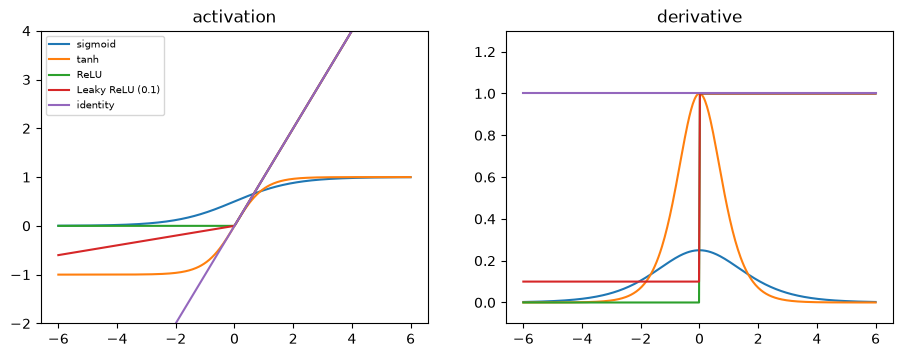

In [1]:
import sys; sys.path.insert(0, '../../src')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
np.set_printoptions(precision=3, suppress=True); pd.set_option('display.width', 160)
z = np.linspace(-6, 6, 400)
f = {'sigmoid': 1/(1+np.exp(-z)), 'tanh': np.tanh(z), 'ReLU': np.maximum(0, z), 'Leaky ReLU (0.1)': np.where(z > 0, z, 0.1*z), 'identity': z}
sig = f['sigmoid']; d = {'sigmoid': sig*(1-sig), 'tanh': 1-np.tanh(z)**2, 'ReLU': (z > 0).astype(float), 'Leaky ReLU (0.1)': np.where(z > 0, 1, 0.1), 'identity': np.ones_like(z)}
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for k in f: ax[0].plot(z, f[k], label=k); ax[1].plot(z, d[k], label=k)
ax[0].set_title('activation'); ax[1].set_title('derivative'); ax[0].set_ylim(-2, 4); ax[1].set_ylim(-0.1, 1.3); ax[0].legend(fontsize=7); plt.show()

**Vanishing gradients:** sigmoid's derivative is at most 0.25 and ~0 for |z|>4; multiplying many such factors in backprop shrinks the gradient. **ReLU** has derivative 1 for z>0 (cheap, no saturation) but can 'die' (derivative 0 for z<0); Leaky ReLU keeps a small slope. **Identity** makes the whole network linear.

In [2]:
print('max sigmoid derivative:', d['sigmoid'].max().round(3), '| max tanh derivative:', d['tanh'].max().round(3))

max sigmoid derivative: 0.25 | max tanh derivative: 1.0


## Effect on a real network: MLP on Titanic, same architecture, only the activation changes (5 seeds)

In [3]:
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from arena.evaluate import split
from arena.preprocess import build_preprocessor
import warnings; warnings.filterwarnings('ignore')
rows = []
for s in range(5):
    a, b, c, e = split('clf', s); pre, _ = build_preprocessor(a); Za = pre.fit_transform(a); Zb = pre.transform(b)
    for es in (True, False):
        for act in ['identity', 'logistic', 'tanh', 'relu']:
            m = MLPClassifier((32,), activation=act, alpha=1e-4, max_iter=1000, early_stopping=es, random_state=s).fit(Za, c); p = m.predict(Zb)
            rows.append(dict(early_stopping=es, activation=act, seed=s, epochs=m.n_iter_, accuracy=accuracy_score(e, p), f1_macro=f1_score(e, p, average='macro')))
    p = LogisticRegression(max_iter=1000).fit(Za, c).predict(Zb); rows.append(dict(early_stopping='-', activation='(logreg ref)', seed=s, epochs=np.nan, accuracy=accuracy_score(e, p), f1_macro=f1_score(e, p, average='macro')))
r = pd.DataFrame(rows).groupby(['early_stopping', 'activation'])[['epochs', 'accuracy', 'f1_macro']].agg(['mean', 'std']).round(3); r

epochs         accuracy        f1_macro       
                               mean     std     mean    std     mean    std
early_stopping activation                                                  
False          identity       104.8  10.085    0.831  0.014    0.819  0.017
               logistic       215.0  22.705    0.830  0.010    0.818  0.013
               relu           845.2  94.378    0.844  0.023    0.829  0.028
               tanh          1000.0   0.000    0.825  0.021    0.810  0.025
True           identity        30.2   6.686    0.807  0.024    0.790  0.028
               logistic        22.4  21.617    0.655  0.073    0.504  0.175
               relu            37.2   8.408    0.791  0.024    0.771  0.030
               tanh            29.4   7.197    0.804  0.030    0.787  0.035
-              (logreg ref)     NaN     NaN    0.830  0.015    0.818  0.017

**Reading it.** With early stopping, the sigmoid (logistic) network stops after only ~20 epochs and underfits badly (much lower accuracy, large std): its small gradients make learning slow, so the validation score plateaus and training is cut off. Without early stopping (up to 1000 epochs) all four activations reach about the same accuracy (~0.83, equal to the logistic-regression reference within one std), but sigmoid/tanh/ReLU need many more epochs than identity. Take-away: activations differ mostly in **how fast and how reliably they train**; on this small, nearly linear problem they end up equally accurate. (An identity-activation MLP is just a linear model.)